# Análise integrada de HIV/AIDS, sífilis e indicadores demográficos — São Paulo (2019–2023)

**Notebook de análise reprodutível, com etapas comentadas, resultados e gráficos exportáveis.**

**Questão de análise:** como se distribuem as taxas municipais de HIV/AIDS e sífilis e como se associam à densidade demográfica e à proporção de área urbanizada ao longo de 2019–2023?

**Unidade de observação:** município–ano; os arquivos fornecidos contêm 645 municípios paulistas para 5 anos.

**Atenção às definições:**
- `HIV/AIDS` e `sífilis`: **taxa por 10.000 habitantes**, conforme os nomes das planilhas. Não se presume que seja incidência, prevalência ou outra definição epidemiológica específica sem conhecer a documentação de origem.
- `Densidade demográfica`: **habitantes por km²**.
- `Urbanização`: **km² de área urbanizada / km² totais do município**. É uma proporção territorial; **não** é o percentual de habitantes em área urbana.

> **Aviso metodológico:** a análise é municipal/ecológica e observacional. Associações e regressões não demonstram causalidade. Médias municipais têm *peso igual por município*, não equivalendo a taxas populacionais agregadas do estado. Taxas muito elevadas de municípios pequenos merecem interpretação prudente, pois não há nesta base os numeradores e denominadores que permitiriam avaliar sua estabilidade.

## Etapa 1 — Bibliotecas, aparência e caminhos

**O que será feito:** importar as bibliotecas, definir a pasta de resultados e localizar os quatro arquivos. As figuras terão título, identificação dos eixos e nota explicativa. Os códigos funcionam no Jupyter ou no Google Colab; no Colab, basta enviar os quatro `.xlsx` caso não estejam presentes.

**Bibliotecas utilizadas:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `statsmodels` e `openpyxl` (leitura do Excel). Se necessário, instale-as com `!pip install pandas numpy matplotlib seaborn scipy statsmodels openpyxl`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 170, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 130)

PASTA_PROJETO = Path.cwd()
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
PASTA_FIGURAS = PASTA_RESULTADOS / "graficos"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    "hiv_aids": "AIDS_HIV.xlsx",
    "sifilis": "Sifilis.xlsx",
    "densidade": "Densidade demografica.xlsx",
    "urbanizacao": "Indice de urbanizacao.xlsx",
}
ANOS = [2019, 2020, 2021, 2022, 2023]
UNIDADES = {
    "hiv_aids": "por 10.000 habitantes",
    "sifilis": "por 10.000 habitantes",
    "densidade": "habitantes/km²",
    "urbanizacao": "fração da área municipal",
}


def localizar_arquivo(nome):
    for pasta in (PASTA_PROJETO / "dados", PASTA_PROJETO, Path("/mnt/data"), Path("/content")):
        caminho = pasta / nome
        if caminho.is_file():
            return caminho
    return None

faltando = [nome for nome in ARQUIVOS.values() if localizar_arquivo(nome) is None]
if faltando:
    try:
        from google.colab import files  # utilizado apenas quando executado no Colab
        print("Envie os arquivos ausentes:", ", ".join(faltando))
        files.upload()
    except ImportError:
        pass

CAMINHOS = {chave: localizar_arquivo(nome) for chave, nome in ARQUIVOS.items()}
if any(caminho is None for caminho in CAMINHOS.values()):
    raise FileNotFoundError("Arquivos não encontrados: " + ", ".join(
        ARQUIVOS[chave] for chave, caminho in CAMINHOS.items() if caminho is None
    ))

print("Pasta de trabalho:", PASTA_PROJETO)
print("Pasta dos resultados:", PASTA_RESULTADOS)
for chave, caminho in CAMINHOS.items():
    print(f"  {chave:12s} ← {caminho.name}")


def salvar_figura(nome):
    """Salva figura e a exibe no notebook."""
    plt.savefig(PASTA_FIGURAS / nome, bbox_inches="tight", facecolor="white")
    plt.show()


def salvar_tabela(tabela, nome):
    """Exporta CSV com separador e vírgula decimal próprios para Excel brasileiro."""
    tabela.to_csv(PASTA_RESULTADOS / nome, sep=";", decimal=",", index=False, encoding="utf-8-sig")

Pasta de trabalho: /mnt/data/Projeto_Analise_IST_SP
Pasta dos resultados: /mnt/data/Projeto_Analise_IST_SP/resultados
  hiv_aids     ← AIDS_HIV.xlsx
  sifilis      ← Sifilis.xlsx
  densidade    ← Densidade demografica.xlsx
  urbanizacao  ← Indice de urbanizacao.xlsx


## Etapa 2 — Leitura, padronização e validação

**O que será feito:** ler todas as abas, converter o formato largo (uma coluna por ano) para o formato longo (uma linha por município e ano), e juntar as quatro fontes pela chave única `CD_MUN` + `ano`.

**Por que usar `CD_MUN` em vez do nome?** A grafia dos nomes difere entre os arquivos (por exemplo, acentuação e maiúsculas); o código municipal evita correspondências incorretas.

**Verificações:** unicidade por município–ano, cobertura de anos, ausência de valores negativos e faixa válida para o indicador de urbanização.

In [2]:
def ler_indicador(nome_variavel, caminho):
    bruto = pd.read_excel(caminho, sheet_name=0, engine="openpyxl")
    bruto.columns = [str(col).strip() for col in bruto.columns]
    obrigatorias = {"MUN", "CD_MUN", *map(str, ANOS)}
    ausentes = obrigatorias.difference(bruto.columns)
    if ausentes:
        raise ValueError(f"{caminho.name}: colunas obrigatórias ausentes: {sorted(ausentes)}")

    bruto["CD_MUN"] = pd.to_numeric(bruto["CD_MUN"], errors="raise").astype("Int64").astype(str).str.zfill(7)
    if not bruto["CD_MUN"].str.fullmatch(r"\d{7}").all():
        raise ValueError(f"Código municipal inválido em {caminho.name}")
    if bruto["CD_MUN"].duplicated().any():
        raise ValueError(f"Códigos municipais duplicados em {caminho.name}")

    longo = bruto.melt(
        id_vars=["MUN", "CD_MUN"], value_vars=list(map(str, ANOS)),
        var_name="ano", value_name=nome_variavel,
    )
    longo["ano"] = longo["ano"].astype(int)
    longo[nome_variavel] = pd.to_numeric(longo[nome_variavel], errors="coerce")
    if (longo[nome_variavel].dropna() < 0).any():
        warnings.warn(f"Há valores negativos em {nome_variavel}; verificar a origem.")
    if nome_variavel == "urbanizacao" and (~longo[nome_variavel].dropna().between(0, 1)).any():
        warnings.warn("Urbanização contém valores fora da fração [0, 1].")

    if nome_variavel == "hiv_aids":
        return longo.rename(columns={"MUN": "municipio"})
    return longo.drop(columns=["MUN"])


fontes = {chave: ler_indicador(chave, caminho) for chave, caminho in CAMINHOS.items()}
codigos_base = set(fontes["hiv_aids"]["CD_MUN"].unique())
for chave, tabela in fontes.items():
    codigos = set(tabela["CD_MUN"].unique())
    print(f"{chave:12s}: {len(codigos)} municípios, {len(tabela)} linhas, "
          f"{tabela[chave].isna().sum()} valores ausentes")
    if codigos != codigos_base:
        warnings.warn(f"Conjunto de municípios de {chave} diferente da base HIV/AIDS.")

dados = fontes["hiv_aids"].copy()
for chave in ("sifilis", "densidade", "urbanizacao"):
    dados = dados.merge(fontes[chave], on=["CD_MUN", "ano"], how="inner", validate="one_to_one")

dados = dados.sort_values(["ano", "municipio"]).reset_index(drop=True)
assert not dados.duplicated(["CD_MUN", "ano"]).any(), "Existem chaves município–ano repetidas."
print(f"\nBASE INTEGRADA: {len(dados)} registros, {dados.CD_MUN.nunique()} municípios, "
      f"anos {dados.ano.min()}–{dados.ano.max()}")
display(dados.head(8))
salvar_tabela(dados, "base_municipio_ano.csv")

hiv_aids    : 645 municípios, 3225 linhas, 0 valores ausentes
sifilis     : 645 municípios, 3225 linhas, 0 valores ausentes
densidade   : 645 municípios, 3225 linhas, 0 valores ausentes
urbanizacao : 645 municípios, 3225 linhas, 0 valores ausentes

BASE INTEGRADA: 3225 registros, 645 municípios, anos 2019–2023


,municipio,CD_MUN,ano,hiv_aids,sifilis,densidade,urbanizacao
0,Adamantina,3500105,2019,5.703205,11.406410,85.119289,0.026313
1,Adolfo,3500204,2019,0.000000,0.000000,16.877103,0.006857
2,Aguaí,3500303,2019,5.508883,0.000000,76.503488,0.017442
3,Agudos,3500709,2019,2.687161,0.000000,38.495596,0.010792
4,Alambari,3500758,2019,0.000000,0.000000,37.750539,0.017325
5,Alfredo Marcondes,3500808,2019,0.000000,0.000000,35.033343,0.007838
6,Altair,3500907,2019,0.000000,24.038462,13.290455,0.002347
7,Altinópolis,3501004,2019,0.000000,0.000000,17.421701,0.004152


## Etapa 3 — Qualidade dos dados e dicionário de variáveis

**O que será feito:** quantificar valores ausentes, zeros, amplitudes e números de observações. **Interpretação:** taxa igual a zero pode representar ausência de registros, enquanto valores ausentes indicariam informação não disponibilizada; eles não serão confundidos.

**Regra:** não removeremos taxas altas automaticamente, pois não há fundamento documental para classificá-las como erros.

In [3]:
linhas_qualidade = []
for variavel in ARQUIVOS:
    valores = dados[variavel]
    linhas_qualidade.append({
        "variavel": variavel,
        "unidade": UNIDADES[variavel],
        "observacoes": len(valores),
        "faltantes": int(valores.isna().sum()),
        "zeros": int((valores == 0).sum()),
        "pct_zeros": round(100 * (valores == 0).mean(), 2),
        "minimo": valores.min(),
        "maximo": valores.max(),
        "negativos": int((valores < 0).sum()),
    })
qualidade = pd.DataFrame(linhas_qualidade)
display(qualidade.round(3))
salvar_tabela(qualidade, "qualidade_dos_dados.csv")

if dados[list(ARQUIVOS)].isna().any().any():
    print("AVISO: existem dados ausentes; os testes usarão pares completos.")
else:
    print("Não foram identificados valores ausentes nas quatro variáveis.")
print("Não confundir: urbanização mede proporção de ÁREA urbanizada, não população urbana.")

,variavel,unidade,observacoes,faltantes,zeros,pct_zeros,minimo,maximo,negativos
0,hiv_aids,por 10.000 habitantes,3225,0,1836,56.93,0.000,713.758,0
1,sifilis,por 10.000 habitantes,3225,0,1803,55.91,0.000,100.334,0
2,densidade,habitantes/km²,3225,0,0,0.00,3.512,14593.451,0
3,urbanizacao,fração da área municipal,3225,0,0,0.00,0.000,0.999,0


Não foram identificados valores ausentes nas quatro variáveis.
Não confundir: urbanização mede proporção de ÁREA urbanizada, não população urbana.


## Etapa 4 — Estatística descritiva por ano

**O que será feito:** calcular média, mediana, desvio-padrão, quartis (25% e 75%), mínimo, máximo e proporção de municípios com zero.

**Interpretação:** a *média não ponderada* descreve o município típico de um conjunto com igual peso entre municípios. A mediana e os quartis são particularmente importantes por causa de muitos valores zero e observações extremas. Não calcular uma “taxa estadual” somando ou fazendo a média dessas taxas sem denominadores populacionais.

In [4]:
rotulos = {
    "hiv_aids": "HIV/AIDS",
    "sifilis": "Sífilis",
    "densidade": "Densidade demográfica",
    "urbanizacao": "Fração de área urbanizada",
}

resumos = []
for variavel in ARQUIVOS:
    for ano, grupo in dados.groupby("ano", sort=True):
        serie = grupo[variavel].dropna()
        resumos.append({
            "indicador": rotulos[variavel], "variavel": variavel, "ano": int(ano),
            "n": len(serie), "media": serie.mean(), "mediana": serie.median(),
            "desvio_padrao": serie.std(), "q25": serie.quantile(0.25),
            "q75": serie.quantile(0.75), "minimo": serie.min(),
            "maximo": serie.max(), "pct_zeros": 100 * (serie == 0).mean(),
        })
resumo_anual = pd.DataFrame(resumos)
display(resumo_anual.round(3))
salvar_tabela(resumo_anual, "estatisticas_descritivas_anuais.csv")

resumo_taxas = resumo_anual[resumo_anual["variavel"].isin(["hiv_aids", "sifilis"])]
print("Resumo das médias anuais (taxas por 10 mil habitantes; pesos iguais por município):")
display(resumo_taxas.pivot(index="ano", columns="indicador", values="media").round(2))

,indicador,variavel,ano,n,media,mediana,desvio_padrao,q25,q75,minimo,maximo,pct_zeros
0,HIV/AIDS,hiv_aids,2019,645,16.014,0.000,58.400,0.000,8.940,0.000,630.835,56.279
1,HIV/AIDS,hiv_aids,2020,645,12.113,0.000,42.524,0.000,6.368,0.000,523.169,61.395
2,HIV/AIDS,hiv_aids,2021,645,12.448,0.000,43.624,0.000,7.161,0.000,713.758,59.070
3,HIV/AIDS,hiv_aids,2022,645,15.392,0.000,47.154,0.000,9.589,0.000,447.344,53.953
4,HIV/AIDS,hiv_aids,2023,645,6.473,0.000,14.558,0.000,7.276,0.000,146.359,53.953
5,Sífilis,sifilis,2019,645,4.747,0.000,8.759,0.000,6.091,0.000,56.338,56.434
6,Sífilis,sifilis,2020,645,4.218,0.000,7.408,0.000,5.866,0.000,51.335,57.829
7,Sífilis,sifilis,2021,645,5.319,0.000,9.590,0.000,7.866,0.000,95.465,54.574
8,Sífilis,sifilis,2022,645,4.826,0.000,8.579,0.000,7.589,0.000,100.334,55.349
9,Sífilis,sifilis,2023,645,4.865,0.000,8.586,0.000,7.828,0.000,99.174,55.349


Resumo das médias anuais (taxas por 10 mil habitantes; pesos iguais por município):


indicador,HIV/AIDS,Sífilis
ano,,
2019,16.01,4.75
2020,12.11,4.22
2021,12.45,5.32
2022,15.39,4.83
2023,6.47,4.87


## Etapa 5 — Gráfico 1: evolução anual das taxas de HIV/AIDS e sífilis

**O que será feito:** comparar as médias e medianas municipais em cada ano.

**Legenda:** linhas contínuas representam médias municipais; linhas tracejadas, medianas. **Importante:** a variação ao longo do tempo pode refletir mudanças de notificação, cobertura ou definição do indicador; não confirma por si só aumento ou queda da ocorrência real.

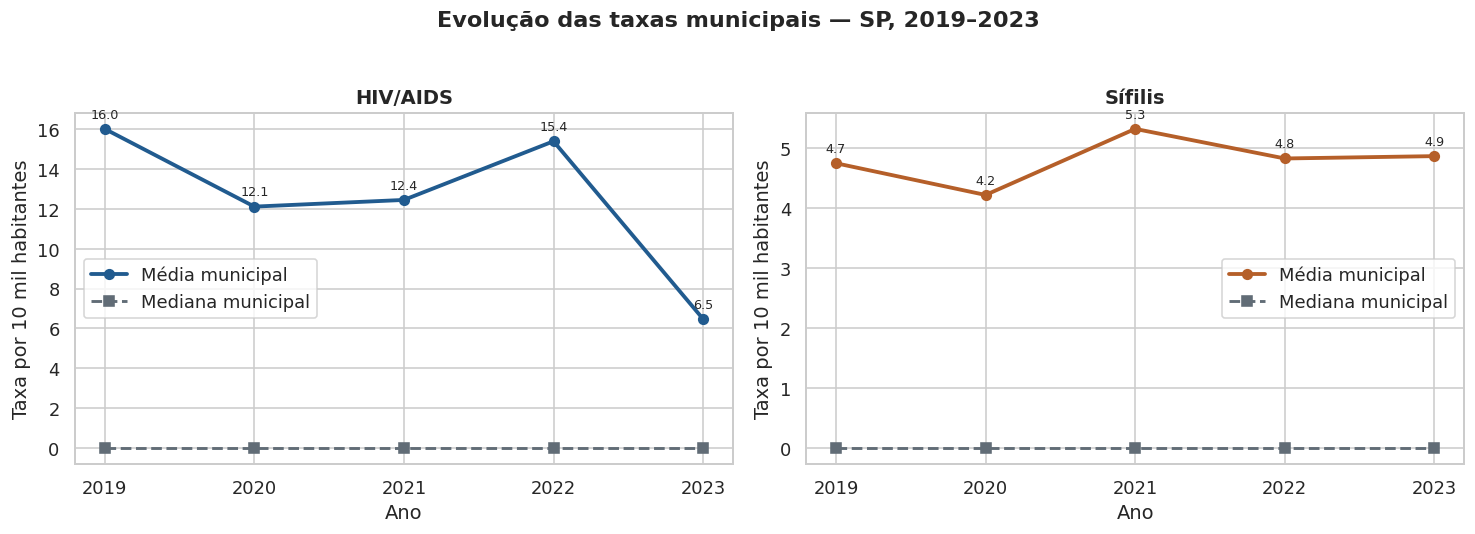

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
cores = {"hiv_aids": "#215B8F", "sifilis": "#B55F29"}
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    t = resumo_anual.query("variavel == @variavel").sort_values("ano")
    ax.plot(t.ano, t.media, "o-", lw=2.4, color=cores[variavel], label="Média municipal")
    ax.plot(t.ano, t.mediana, "s--", lw=1.8, color="#616C76", label="Mediana municipal")
    ax.set(title=rotulos[variavel], xlabel="Ano", ylabel="Taxa por 10 mil habitantes")
    ax.set_xticks(ANOS)
    ax.legend(frameon=True)
    for ano, media in zip(t.ano, t.media):
        ax.annotate(f"{media:.1f}", (ano, media), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
fig.suptitle("Evolução das taxas municipais — SP, 2019–2023", y=1.03, fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("01_evolucao_anual.png")

## Etapa 6 — Gráfico 2: distribuição e valores extremos

**O que será feito:** examinar a variabilidade entre municípios usando boxplots por ano.

**Legenda:** a linha dentro da caixa é a mediana; a caixa cobre os quartis 25–75%; pontos além dos limites usuais do boxplot são observações extremas, **não necessariamente erros**. Como as distribuições têm muitos zeros e valores elevados, usamos `log(1 + taxa)` apenas na visualização. O valor original permanece intacto na base.

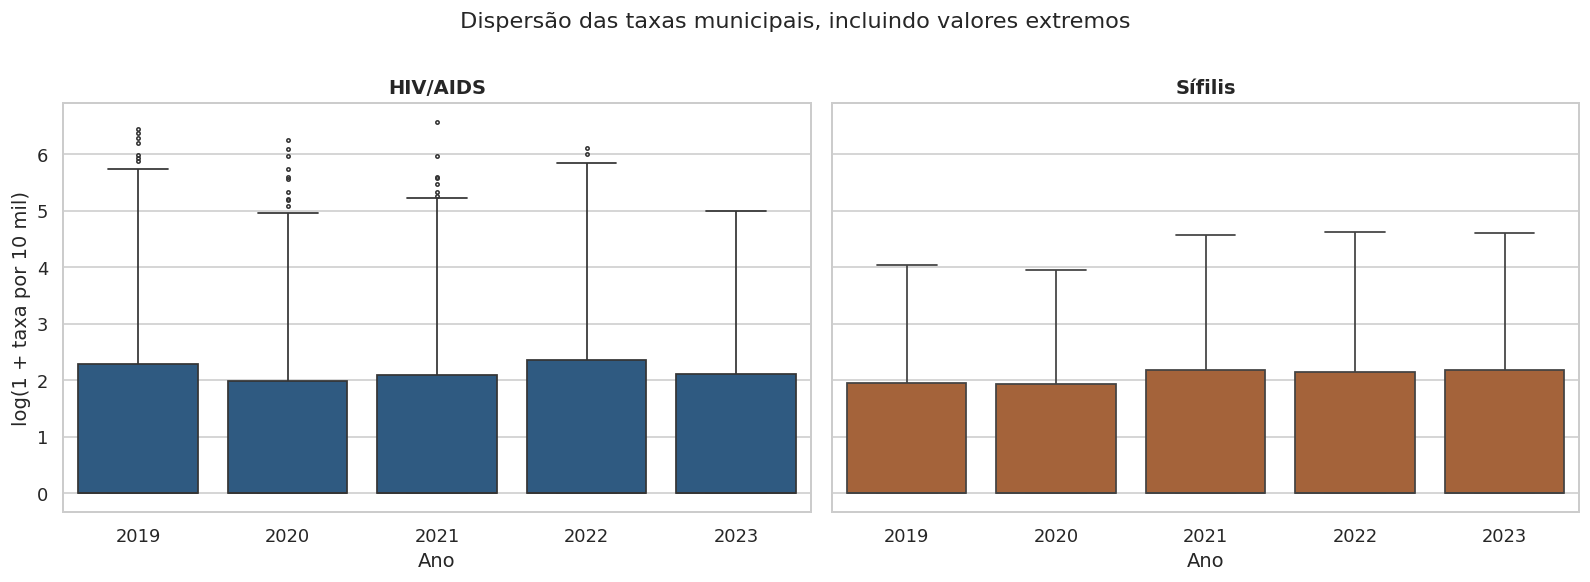

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    t = dados[["ano", variavel]].copy()
    t["taxa_log"] = np.log1p(t[variavel])
    sns.boxplot(data=t, x="ano", y="taxa_log", color=cores[variavel],
                fliersize=2.1, linewidth=1.1, ax=ax)
    ax.set(title=rotulos[variavel], xlabel="Ano", ylabel="log(1 + taxa por 10 mil)")
fig.suptitle("Dispersão das taxas municipais, incluindo valores extremos", y=1.01, fontsize=14)
fig.tight_layout()
salvar_figura("02_distribuicao_boxplots.png")

## Etapa 7 — Gráfico 3: municípios com taxa registrada igual a zero

**O que será feito:** mostrar o percentual de municípios com valor igual a zero para cada doença em cada ano.

**Interpretação:** esse percentual é calculado sobre **municípios**, não sobre pessoas. Um zero na base pode ter significados distintos dependendo da origem e da metodologia de registro.

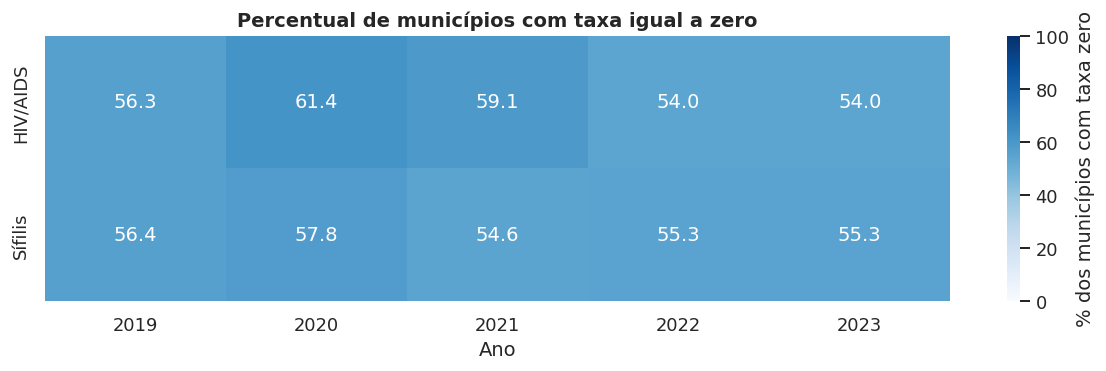

In [7]:
tabela_zeros = resumo_taxas.pivot(index="indicador", columns="ano", values="pct_zeros")
fig, ax = plt.subplots(figsize=(10.5, 3.4))
sns.heatmap(tabela_zeros, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% dos municípios com taxa zero"}, ax=ax)
ax.set(title="Percentual de municípios com taxa igual a zero", xlabel="Ano", ylabel="")
fig.tight_layout()
salvar_figura("03_percentual_zeros.png")

## Etapa 8 — Correlações de Spearman por ano (com correção para múltiplos testes)

**O que será feito:** estimar a correlação de postos de Spearman (`ρ`) entre as taxas de infecção e os indicadores demográficos, além da relação HIV/AIDS–sífilis.

**Por que Spearman?** Há muitos valores zero, assimetria e observações extremas; Spearman é uma medida de associação monotônica baseada em postos. Cada ano é analisado separadamente, sem tratar os cinco registros do mesmo município como observações independentes no teste.

**Inferência:** são feitas 25 comparações (5 pares × 5 anos). Os valores de `p` são ajustados por Benjamini–Hochberg (FDR). `ρ` próximo de +1 indica associação positiva; próximo de −1, negativa; próximo de 0, pouca associação monotônica. Significância estatística **não** equivale a relevância clínica nem a causalidade.

In [8]:
pares = [
    ("hiv_aids", "sifilis"),
    ("hiv_aids", "densidade"),
    ("hiv_aids", "urbanizacao"),
    ("sifilis", "densidade"),
    ("sifilis", "urbanizacao"),
]
resultados_corr = []
for ano, grupo in dados.groupby("ano", sort=True):
    for x, y in pares:
        pares_validos = grupo[[x, y]].dropna()
        rho, p_valor = spearmanr(pares_validos[x], pares_validos[y])
        resultados_corr.append({
            "ano": int(ano), "variavel_1": x, "variavel_2": y,
            "comparacao": f"{rotulos[x]} × {rotulos[y]}",
            "n": len(pares_validos), "rho_spearman": float(rho),
            "p_bruto": float(p_valor),
        })
correlacoes = pd.DataFrame(resultados_corr)
correlacoes["p_fdr"] = multipletests(correlacoes["p_bruto"], method="fdr_bh")[1]
correlacoes["significativo_fdr_5pct"] = correlacoes["p_fdr"] < 0.05
display(correlacoes.round({"rho_spearman": 3, "p_bruto": 5, "p_fdr": 5}))
salvar_tabela(correlacoes, "correlacoes_spearman_por_ano.csv")

,ano,variavel_1,variavel_2,comparacao,n,rho_spearman,p_bruto,p_fdr,significativo_fdr_5pct
0,2019,hiv_aids,sifilis,HIV/AIDS × Sífilis,645,0.027,0.49200,0.51250,False
1,2019,hiv_aids,densidade,HIV/AIDS × Densidade demográfica,645,0.090,0.02252,0.02681,True
2,2019,hiv_aids,urbanizacao,HIV/AIDS × Fração de área urbanizada,645,0.092,0.01908,0.02510,True
3,2019,sifilis,densidade,Sífilis × Densidade demográfica,645,0.318,0.00000,0.00000,True
4,2019,sifilis,urbanizacao,Sífilis × Fração de área urbanizada,645,0.326,0.00000,0.00000,True
5,2020,hiv_aids,sifilis,HIV/AIDS × Sífilis,645,0.077,0.05110,0.05806,False
6,2020,hiv_aids,densidade,HIV/AIDS × Densidade demográfica,645,0.098,0.01300,0.01911,True
7,2020,hiv_aids,urbanizacao,HIV/AIDS × Fração de área urbanizada,645,0.127,0.00118,0.00227,True
8,2020,sifilis,densidade,Sífilis × Densidade demográfica,645,0.449,0.00000,0.00000,True
9,2020,sifilis,urbanizacao,Sífilis × Fração de área urbanizada,645,0.431,0.00000,0.00000,True


## Etapa 9 — Gráficos 4 e 5: evolução das correlações e matriz de 2023

**O que será feito:** visualizar o comportamento de `ρ` por ano e a matriz completa de correlações entre as quatro variáveis no último ano disponível.

**Legenda:** cores indicam valores positivos ou negativos de Spearman; a linha pontilhada horizontal representa associação nula (`ρ = 0`). A matriz refere-se exclusivamente a 2023, evitando duplicar observações de cada município.

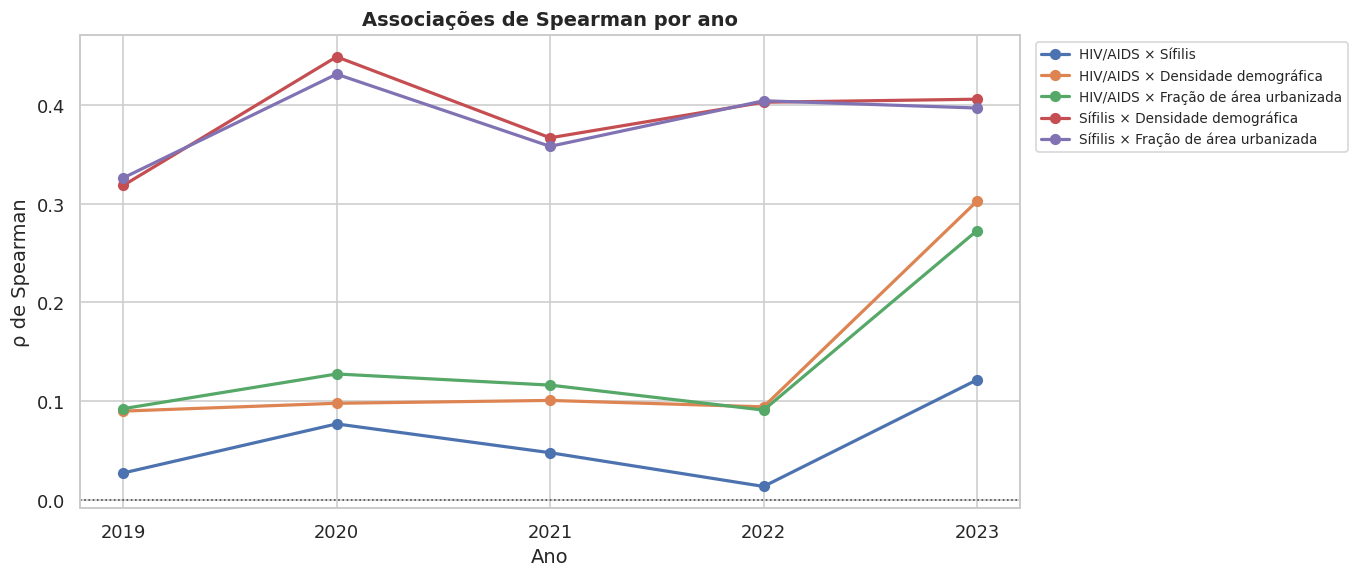

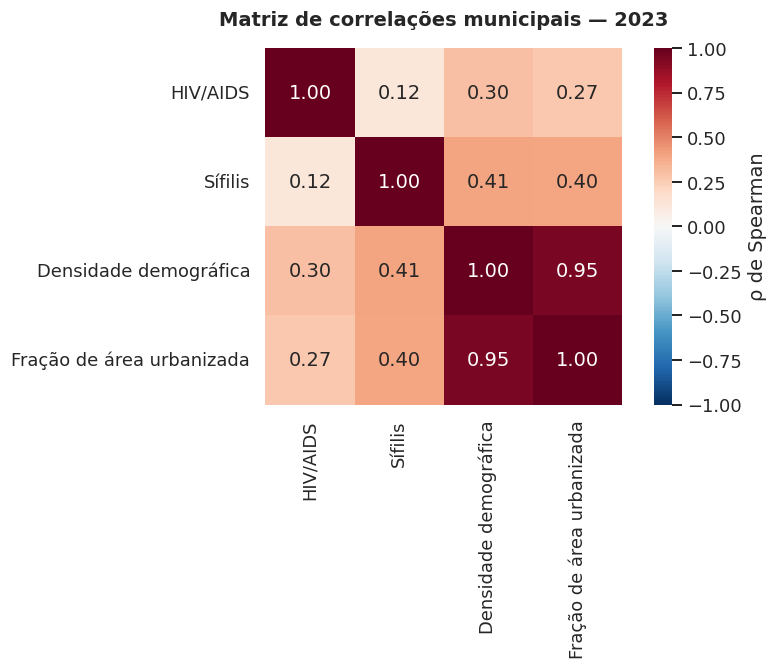

In [9]:
fig, ax = plt.subplots(figsize=(12, 5.2))
for nome, grupo in correlacoes.groupby("comparacao", sort=False):
    ax.plot(grupo.ano, grupo.rho_spearman, marker="o", lw=2, label=nome)
ax.axhline(0, color="#444444", linestyle=":", lw=1)
ax.set(title="Associações de Spearman por ano", xlabel="Ano", ylabel="ρ de Spearman", xticks=ANOS)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8.5, frameon=True)
fig.tight_layout()
salvar_figura("04_evolucao_correlacoes.png")

ultimo_ano = max(ANOS)
dados_2023 = dados[dados.ano == ultimo_ano].copy()
matriz = dados_2023[list(ARQUIVOS)].corr(method="spearman")
matriz = matriz.rename(index=rotulos, columns=rotulos)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "ρ de Spearman"}, ax=ax)
ax.set_title(f"Matriz de correlações municipais — {ultimo_ano}", pad=14)
fig.tight_layout()
salvar_figura("05_matriz_correlacao_2023.png")

## Etapa 10 — Gráfico 6: dispersão das taxas e indicadores territoriais em 2023

**O que será feito:** produzir quatro diagramas de dispersão (duas doenças × dois indicadores territoriais), com linha de tendência local (`LOWESS`, apenas descritiva).

**Escalas:** usamos `log(1 + densidade)` e `log(1 + taxa)` para facilitar a visualização; a urbanização é convertida para **percentual da área do município** (`fração × 100`). Os valores não são substituídos na análise de Spearman.

**Legenda:** cada ponto representa um município; a linha suavizada descreve a forma da relação, não um efeito causal. O coeficiente `ρ` apresentado em cada painel é o de Spearman calculado para 2023.

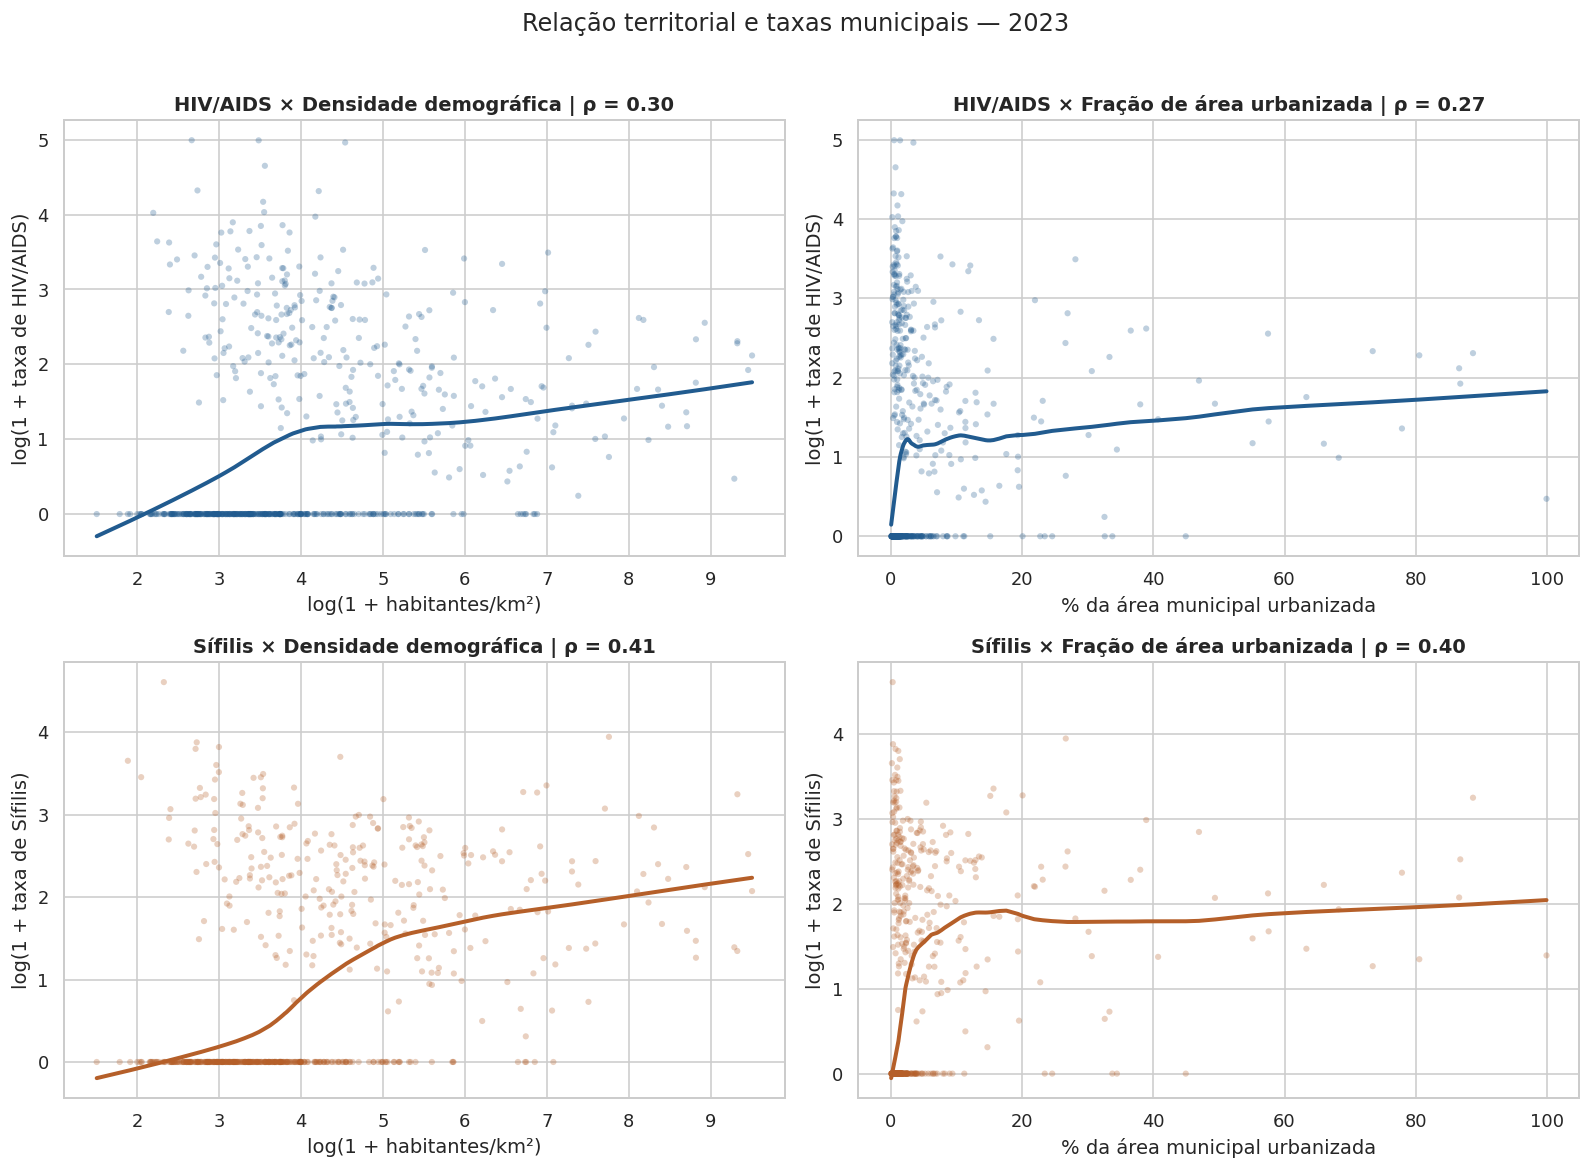

In [10]:
dados_2023["log_densidade"] = np.log1p(dados_2023["densidade"])
dados_2023["urbanizacao_pct_area"] = dados_2023["urbanizacao"] * 100
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))
for i, desfecho in enumerate(("hiv_aids", "sifilis")):
    dados_2023[f"log_{desfecho}"] = np.log1p(dados_2023[desfecho])
    for j, (preditor, eixo_x) in enumerate((("densidade", "log_densidade"),
                                          ("urbanizacao", "urbanizacao_pct_area"))):
        ax = eixos[i, j]
        sns.regplot(data=dados_2023, x=eixo_x, y=f"log_{desfecho}", lowess=True,
                    ci=None, ax=ax, color=cores[desfecho],
                    scatter_kws={"s": 15, "alpha": 0.29, "edgecolor": "none"},
                    line_kws={"lw": 2.5})
        linha = correlacoes[(correlacoes.ano == ultimo_ano)
                            & (correlacoes.variavel_1 == desfecho)
                            & (correlacoes.variavel_2 == preditor)].iloc[0]
        ax.set(title=f"{rotulos[desfecho]} × {rotulos[preditor]} | ρ = {linha.rho_spearman:.2f}",
               ylabel=f"log(1 + taxa de {rotulos[desfecho]})",
               xlabel=("log(1 + habitantes/km²)" if j == 0 else "% da área municipal urbanizada"))
fig.suptitle("Relação territorial e taxas municipais — 2023", y=1.015, fontsize=15)
fig.tight_layout()
salvar_figura("06_dispersoes_indicadores_2023.png")

## Etapa 11 — Gráfico 7: municípios com maiores taxas observadas em 2023

**O que será feito:** identificar os 10 maiores valores para cada doença em 2023.

**Atenção:** os resultados são *taxas por 10 mil*, não números absolutos de casos. A ordenação pode oscilar muito em municípios de pequena população e não deve ser usada isoladamente para definir prioridades sanitárias.

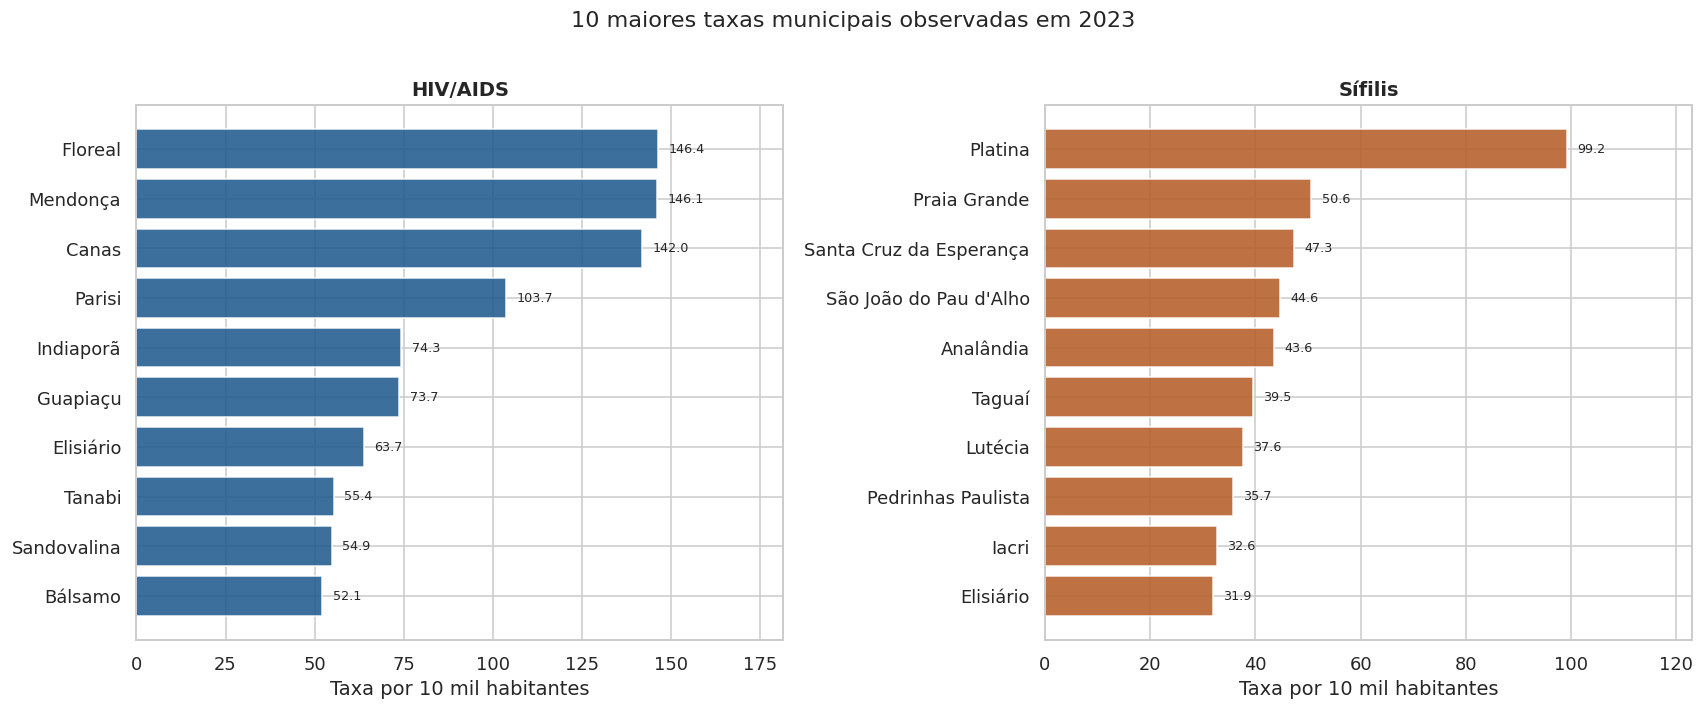

,indicador,municipio,CD_MUN,taxa_por_10mil
0,HIV/AIDS,Floreal,3515905,146.359312
1,HIV/AIDS,Mendonça,3529500,146.127618
2,HIV/AIDS,Canas,3509957,141.959035
3,HIV/AIDS,Parisi,3536257,103.734440
4,HIV/AIDS,Indiaporã,3520707,74.349442
5,HIV/AIDS,Guapiaçu,3517505,73.695362
6,HIV/AIDS,Elisiário,3514924,63.734863
7,HIV/AIDS,Tanabi,3553401,55.412626
8,HIV/AIDS,Sandovalina,3545506,54.869684
9,HIV/AIDS,Bálsamo,3504800,52.105044


In [11]:
top10_tabelas = []
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.1))
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    top = dados_2023.nlargest(10, variavel)[["municipio", "CD_MUN", variavel]].copy()
    top = top.rename(columns={variavel: "taxa_por_10mil"})
    top.insert(0, "indicador", rotulos[variavel])
    top10_tabelas.append(top)
    plotagem = top.sort_values("taxa_por_10mil")
    ax.barh(plotagem["municipio"], plotagem["taxa_por_10mil"], color=cores[variavel], alpha=0.88)
    ax.set(title=rotulos[variavel], xlabel="Taxa por 10 mil habitantes", ylabel="")
    ax.set_xlim(0, plotagem.taxa_por_10mil.max() * 1.24)
    for idx, valor in enumerate(plotagem["taxa_por_10mil"]):
        ax.text(valor + plotagem.taxa_por_10mil.max() * 0.02, idx, f"{valor:.1f}", va="center", fontsize=8)
fig.suptitle("10 maiores taxas municipais observadas em 2023", fontsize=14, y=1.01)
fig.tight_layout()
salvar_figura("07_top_10_municipios_2023.png")
top10 = pd.concat(top10_tabelas, ignore_index=True)
salvar_tabela(top10, "top10_taxas_2023.csv")
display(top10)

## Etapa 12 — Modelagem exploratória (painel município–ano)

**O que será feito:** ajustar separadamente dois modelos de regressão linear para `log(1 + taxa)`, cada um com `log(1 + densidade)`, proporção territorial urbanizada (em **10 pontos percentuais**) e **efeitos fixos de ano**. Os erros-padrão serão robustos e agrupados por município, pois o mesmo município aparece em cinco anos.

**Leitura dos coeficientes:** são associações condicionais na escala `log(1+taxa)`; não são mudanças em número de casos nem efeitos causais. A análise não ajusta por idade, sexo, acesso a testes, notificação, desigualdade ou tamanho populacional. A medida de área urbanizada pode estar correlacionada com densidade. O modelo é **exploratório** e não uma inferência epidemiológica definitiva.

**Por que transformar as taxas?** Muitos zeros e caudas longas tornam a distribuição muito assimétrica. `log1p` aceita zero; ainda assim, o ajuste por mínimos quadrados não substitui modelos de contagem com numeradores e denominadores disponíveis.

In [12]:
modelagem = dados.copy()
modelagem["log_densidade"] = np.log1p(modelagem["densidade"])
modelagem["urbanizacao_10pp"] = modelagem["urbanizacao"] * 10  # 1 unidade = 10 pontos percentuais da área
modelos = {}
linhas_modelos = []
for desfecho in ("hiv_aids", "sifilis"):
    coluna = f"log_taxa_{desfecho}"
    modelagem[coluna] = np.log1p(modelagem[desfecho])
    formula = f"{coluna} ~ log_densidade + urbanizacao_10pp + C(ano)"
    m = smf.ols(formula, data=modelagem).fit(
        cov_type="cluster", cov_kwds={"groups": modelagem["CD_MUN"]}
    )
    modelos[desfecho] = m
    for termo in ("log_densidade", "urbanizacao_10pp"):
        ci_inf, ci_sup = m.conf_int().loc[termo]
        linhas_modelos.append({
            "desfecho": rotulos[desfecho], "variavel": termo,
            "coeficiente": m.params[termo], "ic95_inferior": ci_inf,
            "ic95_superior": ci_sup, "p_valor": m.pvalues[termo],
            "r2": m.rsquared, "observacoes": int(m.nobs),
            "municipios_agrupamento": modelagem.CD_MUN.nunique(),
        })

coeficientes = pd.DataFrame(linhas_modelos)
print("Coeficientes selecionados dos modelos, com erros-padrão agrupados por município:")
display(coeficientes.round(5))
salvar_tabela(coeficientes, "modelos_painel_coeficientes.csv")
print("\nR² de cada modelo e tamanho amostral:")
for desfecho, m in modelos.items():
    print(f"{rotulos[desfecho]}: n={int(m.nobs)}, R²={m.rsquared:.3f}")

Coeficientes selecionados dos modelos, com erros-padrão agrupados por município:


,desfecho,variavel,coeficiente,ic95_inferior,ic95_superior,p_valor,r2,observacoes,municipios_agrupamento
0,HIV/AIDS,log_densidade,0.01971,-0.06780,0.10722,0.65891,0.00337,3225,645
1,HIV/AIDS,urbanizacao_10pp,0.00685,-0.08186,0.09555,0.87976,0.00337,3225,645
2,Sífilis,log_densidade,0.38352,0.31683,0.45021,0.00000,0.13000,3225,645
3,Sífilis,urbanizacao_10pp,-0.15154,-0.22912,-0.07397,0.00013,0.13000,3225,645



R² de cada modelo e tamanho amostral:
HIV/AIDS: n=3225, R²=0.003
Sífilis: n=3225, R²=0.130


## Etapa 13 — Gráfico 8: coeficientes estimados e intervalos de confiança

**O que será feito:** apresentar os dois preditores de cada modelo com seu intervalo de confiança de 95%.

**Legenda:** pontos indicam coeficientes estimados na escala `log(1+taxa)`; barras horizontais representam intervalos de confiança de 95%; a linha vertical em zero representa ausência de associação no modelo. Os preditores **não estão na mesma unidade**, portanto seus tamanhos não devem ser comparados diretamente como “importância”.

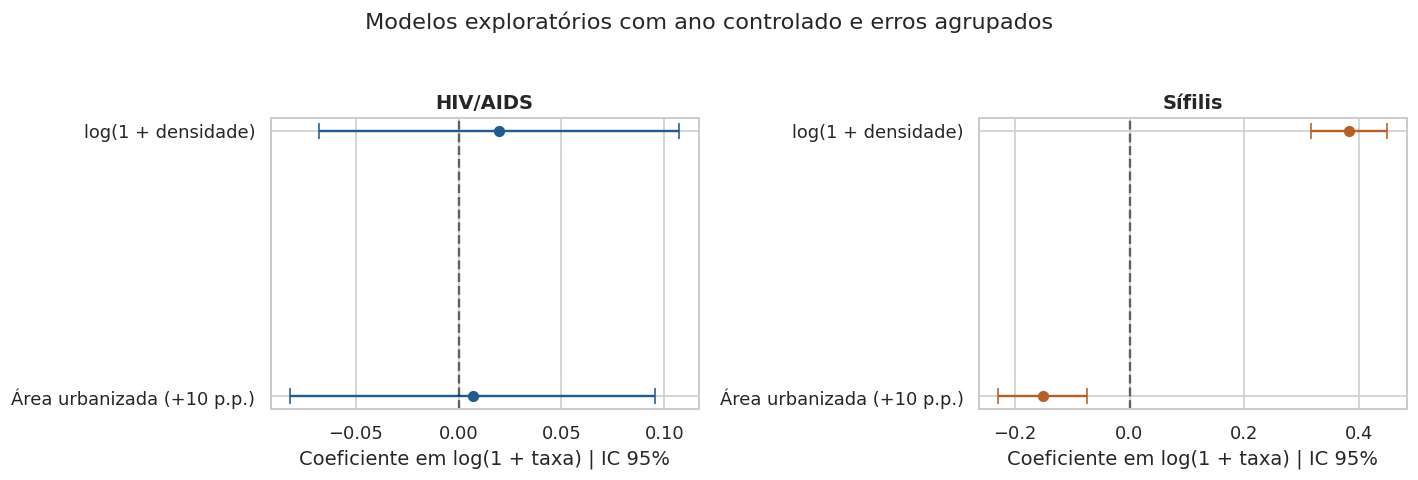

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4), sharex=False)
nomes_termos = {
    "log_densidade": "log(1 + densidade)",
    "urbanizacao_10pp": "Área urbanizada (+10 p.p.)",
}
for ax, desfecho in zip(eixos, ("HIV/AIDS", "Sífilis")):
    t = coeficientes[coeficientes.desfecho == desfecho].reset_index(drop=True)
    for i, linha in t.iterrows():
        ax.errorbar(linha.coeficiente, i,
                    xerr=[[linha.coeficiente - linha.ic95_inferior],
                          [linha.ic95_superior - linha.coeficiente]],
                    fmt="o", capsize=5, color="#215B8F" if desfecho == "HIV/AIDS" else "#B55F29")
    ax.axvline(0, ls="--", color="black", alpha=0.55)
    ax.set_yticks(range(len(t)), labels=[nomes_termos[z] for z in t.variavel])
    ax.set(title=desfecho, xlabel="Coeficiente em log(1 + taxa) | IC 95%")
    ax.invert_yaxis()
fig.suptitle("Modelos exploratórios com ano controlado e erros agrupados", y=1.04, fontsize=14)
fig.tight_layout()
salvar_figura("08_coeficientes_modelos.png")

## Etapa 14 — Síntese automática dos principais resultados

**O que será feito:** montar um resumo textual reprodutível, preenchido pelos números que o notebook calculou. Assim, o texto será atualizado caso as planilhas sejam substituídas e o notebook seja reexecutado.

**Legenda de interpretação:** `ρ` é a correlação de Spearman; `p_FDR` é o valor de significância ajustado para múltiplos testes. O texto distingue **resultados observados** de **limitações de interpretação**.

In [14]:
def formatar(v, casas=2):
    return f"{v:.{casas}f}".replace(".", ",")

media_2023 = resumo_taxas[resumo_taxas.ano == 2023].set_index("variavel")
media_2022 = resumo_taxas[resumo_taxas.ano == 2022].set_index("variavel")

linhas_relatorio = [
    "# Síntese automática — HIV/AIDS, sífilis e ambiente municipal — SP (2019–2023)",
    "",
    f"- Base: **{dados.CD_MUN.nunique()} municípios**, **{dados.ano.nunique()} anos**, "
    f"**{len(dados)} observações município–ano**.",
    "- Fontes: quatro planilhas fornecidas para este estudo, sem verificação externa de suas definições.",
    "- Os indicadores HIV/AIDS e sífilis são apresentados como taxas por **10 mil habitantes**; "
    "urbanização é **fração da área territorial urbanizada**, não da população urbana.",
    "",
    "## Descrição de 2023",
]
for variavel in ("hiv_aids", "sifilis"):
    linha = media_2023.loc[variavel]
    anterior = media_2022.loc[variavel, "media"]
    variacao = 100 * (linha["media"] / anterior - 1) if anterior != 0 else float("nan")
    linhas_relatorio.append(
        f"- {rotulos[variavel]}: média municipal **{formatar(linha['media'])}** por 10 mil, "
        f"mediana **{formatar(linha['mediana'])}**, "
        f"**{formatar(linha['pct_zeros'], 1)}%** dos municípios com taxa zero. "
        f"Em comparação a 2022, a média municipal variou **{formatar(variacao,1)}%** "
        "(comparação descritiva, não necessariamente mudança epidemiológica)."
    )

linhas_relatorio += ["", "## Correlações de Spearman em 2023 (ajuste FDR em 25 testes)"]
for _, l in correlacoes[correlacoes.ano == 2023].iterrows():
    linhas_relatorio.append(
        f"- {l.comparacao}: **ρ = {formatar(l.rho_spearman,3)}**, "
        f"p_FDR = {l.p_fdr:.3g}; "
        f"{'significativo' if l.significativo_fdr_5pct else 'não significativo'} ao nível de 5%."
    )
linhas_relatorio += [
    "", "## Modelagem exploratória", 
    "- Foram estimados modelos para log(1 + taxa), com efeitos de ano, densidade e fração de área urbanizada, "
    "e erros-padrão agrupados por município. Coeficientes e IC 95%: ver modelos_painel_coeficientes.csv.",
    "", "## Limitações importantes",
    "- Estudo ecológico, observacional, sem identificação de mecanismos causais.",
    "- Médias não ponderadas por população municipal **não são** taxas estaduais agregadas.",
    "- Taxas altas em municípios pequenos podem variar muito de ano para ano.",
    "- A grande frequência de zeros exige cautela; o significado de zero depende da fonte.",
    "- É necessário consultar metadados originais antes de denominar as taxas como incidência ou prevalência.",
    "- Não se avaliou completude de notificação, mudanças de definição, COVID-19, testagem ou estrutura etária.",
]
relatorio = "\n".join(linhas_relatorio) + "\n"
(PASTA_RESULTADOS / "resumo_resultados.md").write_text(relatorio, encoding="utf-8")
display(Markdown(relatorio))

# Síntese automática — HIV/AIDS, sífilis e ambiente municipal — SP (2019–2023)

- Base: **645 municípios**, **5 anos**, **3225 observações município–ano**.
- Fontes: quatro planilhas fornecidas para este estudo, sem verificação externa de suas definições.
- Os indicadores HIV/AIDS e sífilis são apresentados como taxas por **10 mil habitantes**; urbanização é **fração da área territorial urbanizada**, não da população urbana.

## Descrição de 2023
- HIV/AIDS: média municipal **6,47** por 10 mil, mediana **0,00**, **54,0%** dos municípios com taxa zero. Em comparação a 2022, a média municipal variou **-57,9%** (comparação descritiva, não necessariamente mudança epidemiológica).
- Sífilis: média municipal **4,87** por 10 mil, mediana **0,00**, **55,3%** dos municípios com taxa zero. Em comparação a 2022, a média municipal variou **0,8%** (comparação descritiva, não necessariamente mudança epidemiológica).

## Correlações de Spearman em 2023 (ajuste FDR em 25 testes)
- HIV/AIDS × Sífilis: **ρ = 0,122**, p_FDR = 0.00354; significativo ao nível de 5%.
- HIV/AIDS × Densidade demográfica: **ρ = 0,303**, p_FDR = 8.89e-15; significativo ao nível de 5%.
- HIV/AIDS × Fração de área urbanizada: **ρ = 0,273**, p_FDR = 3.73e-12; significativo ao nível de 5%.
- Sífilis × Densidade demográfica: **ρ = 0,406**, p_FDR = 4.61e-26; significativo ao nível de 5%.
- Sífilis × Fração de área urbanizada: **ρ = 0,397**, p_FDR = 3.71e-25; significativo ao nível de 5%.

## Modelagem exploratória
- Foram estimados modelos para log(1 + taxa), com efeitos de ano, densidade e fração de área urbanizada, e erros-padrão agrupados por município. Coeficientes e IC 95%: ver modelos_painel_coeficientes.csv.

## Limitações importantes
- Estudo ecológico, observacional, sem identificação de mecanismos causais.
- Médias não ponderadas por população municipal **não são** taxas estaduais agregadas.
- Taxas altas em municípios pequenos podem variar muito de ano para ano.
- A grande frequência de zeros exige cautela; o significado de zero depende da fonte.
- É necessário consultar metadados originais antes de denominar as taxas como incidência ou prevalência.
- Não se avaliou completude de notificação, mudanças de definição, COVID-19, testagem ou estrutura etária.


## Etapa 15 — Arquivos gerados e próximos passos científicos

**O que foi produzido:** uma tabela integrada município–ano, estatísticas anuais, controle de qualidade, correlações corrigidas para múltiplos testes, rankings, coeficientes de modelos, oito arquivos PNG com gráficos e um resumo em Markdown. O diretório `resultados/` pode ser compactado e distribuído com o notebook.

**Para aprofundar a pesquisa:** conferir a definição dos indicadores na fonte; obter população municipal por ano e números absolutos de casos para calcular taxas estaduais ponderadas e intervalos de incerteza; examinar a estabilidade dos extremos; considerar estrutura etária, testagem e cobertura da vigilância. **Não é possível inferir características individuais dos moradores a partir destas correlações municipais.**

In [15]:
produzidos = sorted(x.relative_to(PASTA_PROJETO).as_posix() for x in PASTA_RESULTADOS.rglob("*") if x.is_file())
print(f"Total de arquivos de resultado: {len(produzidos)}")
for nome in produzidos:
    print("•", nome)
print("\nNotebook finalizado. Todas as tabelas, gráficos e conclusões foram calculados das planilhas fornecidas.")

Total de arquivos de resultado: 15
• resultados/base_municipio_ano.csv
• resultados/correlacoes_spearman_por_ano.csv
• resultados/estatisticas_descritivas_anuais.csv
• resultados/graficos/01_evolucao_anual.png
• resultados/graficos/02_distribuicao_boxplots.png
• resultados/graficos/03_percentual_zeros.png
• resultados/graficos/04_evolucao_correlacoes.png
• resultados/graficos/05_matriz_correlacao_2023.png
• resultados/graficos/06_dispersoes_indicadores_2023.png
• resultados/graficos/07_top_10_municipios_2023.png
• resultados/graficos/08_coeficientes_modelos.png
• resultados/modelos_painel_coeficientes.csv
• resultados/qualidade_dos_dados.csv
• resultados/resumo_resultados.md
• resultados/top10_taxas_2023.csv

Notebook finalizado. Todas as tabelas, gráficos e conclusões foram calculados das planilhas fornecidas.
